# LeJEPA and Gaussian projections

Two views of a digit should agree, yet different digits should occupy a spread of feature space. LeJEPA combines these goals by measuring how random one-dimensional projections compare with a standard Gaussian.

For each projection, the statistic compares the real and imaginary parts of the empirical characteristic function with exp(−t²/2). Gaussian-weighted trapezoidal integration and averaging over fresh directions give a differentiable regulariser. This version uses two global views and a compact convolutional encoder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, f1_score


def digit_data():
    digits = load_digits()
    train, test = train_test_split(
        np.arange(len(digits.target)), test_size=0.25, stratify=digits.target, random_state=17
    )
    x = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
    return x[train], x[test], digits.target[train], digits.target[test]


def view(x):
    n = len(x)
    padded = F.pad(x, (1, 1, 1, 1))
    offset = torch.randint(3, (n, 2))
    row = offset[:, 0, None, None] + torch.arange(8)[None, :, None]
    col = offset[:, 1, None, None] + torch.arange(8)[None, None, :]
    moved = padded[torch.arange(n)[:, None, None], 0, row, col][:, None]
    return (moved + 0.06 * torch.randn_like(moved)).clamp(0, 1)


@torch.no_grad()
def embed(model, x):
    model.eval()
    return torch.cat([model(batch) for batch in x.split(96)]).flatten(1).numpy()


def compare(initial, trained, x, t, y, yt):
    systems = [
        ("Raw pixels", x.flatten(1).numpy(), t.flatten(1).numpy()),
        ("Random encoder", embed(initial, x), embed(initial, t)),
        ("Trained encoder", embed(trained, x), embed(trained, t)),
    ]
    rows = []
    for name, a, b in systems:
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1200, C=1))
        probe.fit(a, y)
        guess = probe.predict(b)
        power = np.linalg.svd(b - b.mean(0), compute_uv=False) ** 2
        p = power[power > 0] / max(power.sum(), 1e-30)
        rank = float(np.exp(-(p * np.log(p)).sum())) if len(p) else 0.0
        rows.append(
            (
                name,
                float((guess == yt).mean()),
                balanced_accuracy_score(yt, guess),
                f1_score(yt, guess, average="macro"),
                rank,
            )
        )
    report(["Features", "Test accuracy", "Balanced accuracy", "Macro F1", "Effective rank"], rows)


def conv_encoder():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1),
        nn.GELU(),
        nn.AvgPool2d(2),
        nn.Conv2d(16, 24, 3, padding=1),
        nn.GELU(),
        nn.Flatten(),
        nn.Linear(24 * 4 * 4, 32),
    )


def slice_statistic(z, direction, freq):
    projected = z @ direction
    phases = projected[:, :, None] * freq
    target = torch.exp(-0.5 * freq.square())
    discrepancy = (phases.cos().mean(0) - target).square() + phases.sin().mean(0).square()
    return len(z) * torch.trapezoid(discrepancy * target, x=freq, dim=-1).mean()


def directions(width, count, rng):
    return F.normalize(torch.randn(width, count, generator=rng), dim=0)

## Compare the views and regularise their distributions

The two embeddings learn towards their per-image mean. Draw sixteen unit directions per update and use the same directions to evaluate each view separately.

In [2]:
seed()
x, t, y, yt = digit_data()
encoder = conv_encoder()
initial = copy.deepcopy(encoder)
project = nn.Sequential(nn.Linear(32, 48), nn.GELU(), nn.Linear(48, 12))
optim = torch.optim.AdamW([*encoder.parameters(), *project.parameters()], lr=0.002)
freq = torch.linspace(-4, 4, 17)
rng = torch.Generator().manual_seed(47)
curve = []
for epoch in range(22):
    items = []
    for indices in torch.randperm(len(x)).split(80):
        if len(indices) < 24:
            continue
        a = project(encoder(view(x[indices])))
        b = project(encoder(view(x[indices])))
        midpoint = (a + b) / 2
        invariance = ((a - midpoint).square().mean() + (b - midpoint).square().mean()) / 2
        axes = directions(a.shape[1], 16, rng)
        regularity = (slice_statistic(a, axes, freq) + slice_statistic(b, axes, freq)) / 2
        loss = invariance + 0.06 * regularity
        optim.zero_grad()
        loss.backward()
        optim.step()
        items.append([invariance.item(), 0.06 * regularity.item()])
    curve.append(np.mean(items, axis=0))

## Test the feature space

Use the same sample size and the same 64 fixed evaluation directions for the trained embeddings, a Gaussian reference and an all-zero feature cloud.

,Features,Test accuracy,Balanced accuracy,Macro F1,Effective rank
0,Raw pixels,0.97111,0.97084,0.97099,20.17443
1,Random encoder,0.96667,0.96650,0.96657,10.29035
2,Trained encoder,0.75778,0.75553,0.75137,2.14755


,Projection input,Samples,Mean sliced statistic,Mean coordinate SD
0,Constant,450,183.92015,0.00000
1,Gaussian reference,450,0.89028,0.98213
2,Held-out digits,450,96.08559,0.64904


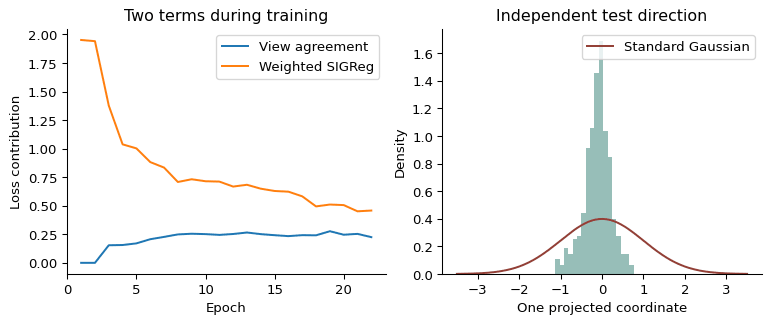

In [3]:
compare(initial, encoder, x, t, y, yt)
project.eval()
with torch.no_grad():
    z = project(encoder(t))
    fixed = torch.Generator().manual_seed(101)
    axes = directions(z.shape[1], 64, fixed)
    gaussian = torch.randn(z.shape, generator=fixed)
    rows = []
    for name, array in [
        ("Constant", torch.zeros_like(z)),
        ("Gaussian reference", gaussian),
        ("Held-out digits", z),
    ]:
        rows.append(
            (name, len(z), slice_statistic(array, axes, freq).item(), array.std(0).mean().item())
        )
    projection = (z @ axes[:, 0]).numpy()
report(["Projection input", "Samples", "Mean sliced statistic", "Mean coordinate SD"], rows)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.3), layout="constrained")
ax[0].plot(np.arange(1, len(curve) + 1), curve)
ax[0].set(xlabel="Epoch", ylabel="Loss contribution", title="Two terms during training")
ax[0].legend(["View agreement", "Weighted SIGReg"])
ax[1].hist(projection, bins=18, density=True, color="#74a9a0", alpha=0.75)
grid = np.linspace(-3.5, 3.5, 160)
ax[1].plot(
    grid, np.exp(-(grid**2) / 2) / np.sqrt(2 * np.pi), color="#933f36", label="Standard Gaussian"
)
ax[1].set(xlabel="One projected coordinate", ylabel="Density", title="Independent test direction")
ax[1].legend()
plt.show()

## Interpreting the result

The held-out sliced statistic was 96.09, between the constant cloud at 183.92 and the finite Gaussian reference at 0.89. The probe reached 75.8%, below the random encoder at 96.7%. This short run leaves substantial room between the learned projection distribution and its target.

A histogram shows one direction, while the table averages discrepancies over 64. Finite samples from a Gaussian also have a positive statistic. The linear probe uses the encoder before the projection head.

## Exercise

Hold the augmentation and split fixed, set the regularisation weight to zero and track which diagnostics detect contraction.

## References

[Balestriero and LeCun (2025), LeJEPA](https://arxiv.org/abs/2511.08544)

[Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)